In [3]:
import os
import re  
import math
import pickle
import zipfile
from collections import defaultdict

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d import Axes3D  

import h5py
from scipy import signal
from scipy.stats import (zscore, ks_2samp, linregress, pearsonr)
from scipy.signal import (convolve, windows, resample)
from scipy.ndimage import gaussian_filter1d

from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import (PolynomialFeatures, StandardScaler)
from sklearn.model_selection import (train_test_split, cross_val_score, KFold)
from sklearn.metrics import r2_score, mean_squared_error
import umap.umap_ as umap


/Users/nmt121/Desktop/Repositories/Motoneuron_Model/.conda/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [21]:
from functions_experimental_data_Bräckleinexp import *

def conv_spikes(array, pos1, pos2, fs, window_duration=0.3):
    window_samples = int(round(window_duration * fs))
    hanning_window = windows.hann(window_samples)
    hanning_window /= np.sum(hanning_window)  
    smoothed_spike_array1 = convolve(array[pos1, :], hanning_window, mode='same') * fs
    smoothed_spike_array2 = convolve(array[pos2, :], hanning_window, mode='same') * fs
    return smoothed_spike_array1, smoothed_spike_array2



## Extract data from the zip file

In [25]:
# ## to save data in folders
# zip_file_path = '/Users/nmt121/Desktop/OneDrive_11_15-02-2025.zip'
# destination_folder = '/Users/nmt121/Desktop/DATA/S7'

# os.makedirs(destination_folder, exist_ok=True)

# with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
#     file_list = zip_ref.namelist()
#     high_files = [file for file in file_list if "High" in file]
#     print(f"Files to extract: {high_files}")    
#     for file in high_files:
#         zip_ref.extract(file, destination_folder)
# print(f"Extraction complete. Files saved to {destination_folder}")


## Start analysis



In [14]:
folder_path = '/Users/nmt121/Desktop/DATA/S1'
Fsamp = 2048

# Function to extract day in "DayXX" format
def extract_day(filename):
    match = re.search(r"(Day\d{2})", filename)
    return int(match.group(1)[3:]) if match else None  # Extract numeric part of "DayXX"

# Function to extract trial number safely
def extract_trial(filename):
    match = re.search(r'_(\d+)[^0-9]', filename)  # Extracts numeric trial number before a non-digit
    return int(match.group(1)) if match else 0  # Default to 0 if no match found

# Sort files by (Day, Trial)
pkl_files = sorted(
    [f for f in os.listdir(folder_path) if f.endswith('.pkl')],
    key=lambda x: (extract_day(x), extract_trial(x))
)

num_files = len(pkl_files)
cols = 3
rows = math.ceil(num_files / cols)

fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows), sharex=False, sharey=True)
axes = axes.flatten()

for idx, file in enumerate(pkl_files):
    file_path = os.path.join(folder_path, file)

    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    data_MU = np.array(data['MU'].tolist())
    idx_pair = data['Idx_MU_Pair'].tolist()

    ax = axes[idx]

    for i in range(data_MU.shape[0]):
        spike_times = np.where(data_MU[i] == 1)[0] / Fsamp

        if i == idx_pair[0]:
            colorline = 'red'
        elif i == idx_pair[1]:
            colorline = 'blue'
        else:
            colorline = 'black'

        ax.vlines(spike_times, i + 0.5, i + 1.5, color=colorline, linewidth=0.5)

    ax.set_title(f'{file}', fontsize=10)
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Neurons')

for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()




### PIPELINE ANALYSIS --------------------------------------------------------------------------------------------------------------------------------------------------

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_47021/3407850340.py:12: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = {day: cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}


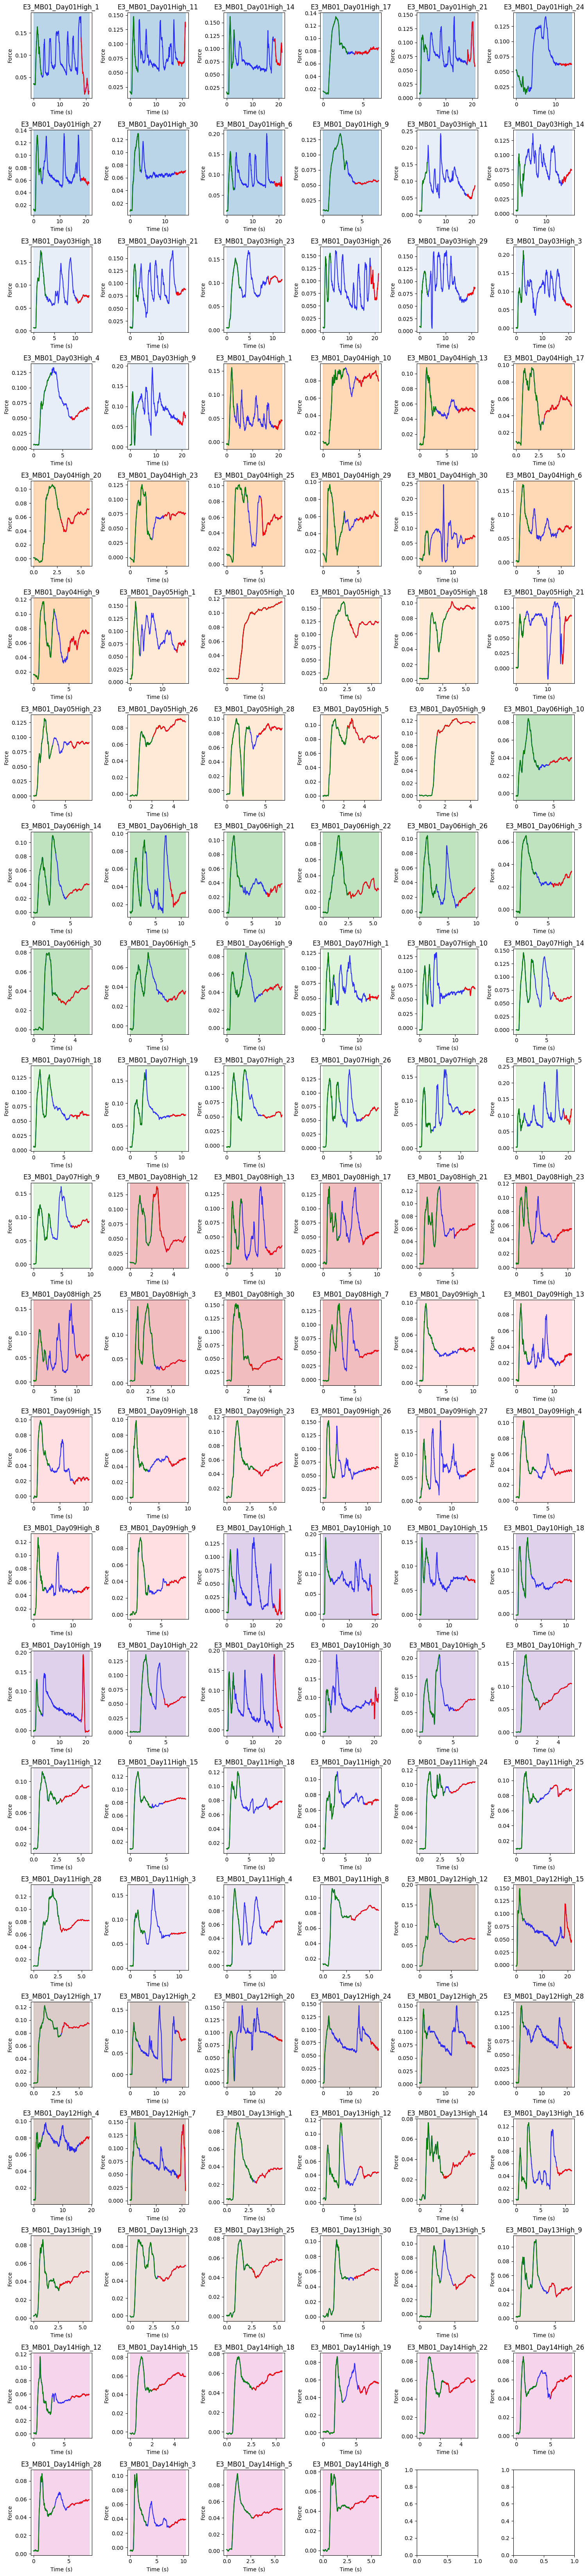

In [15]:
fsamp = 2048  
highlight_samples = int(3 * fsamp)  

directory_path = "/Users/nmt121/Desktop/DATA/S1"
sorted_pkl_files = sorted([f for f in os.listdir(directory_path) if f.endswith(".pkl")])


session_days = sorted(set([extract_day(file) for file in sorted_pkl_files if extract_day(file)]))

num_days = len(session_days)
if num_days <= 20:
    color_map = {day: cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}
else:
    color_map = {day: cm.viridis(i / num_days) for i, day in enumerate(session_days)}  

num_files = len(sorted_pkl_files)
cols = 6  
rows = int(np.ceil(num_files / cols)) 

fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 3))
axes = axes.flatten()

for i, file_name in enumerate(sorted_pkl_files):
    file_path = os.path.join(directory_path, file_name)
    
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    data_FORCE = np.array(data['Force'].tolist())[0]  
    time_axis = np.arange(len(data_FORCE)) / fsamp  

    start_region = np.arange(highlight_samples)  
    end_region = np.arange(len(data_FORCE) - highlight_samples, len(data_FORCE))  

    day_info = extract_day(file_name)  
    day_color = color_map.get(day_info, "white")  

    idx = np.array(data['idx'].tolist()[0])
    data_MU = np.array(data['MU'].tolist())
    data_RATE = np.array(data['DR'].tolist())
    idx_pair = data['Idx_MU_Pair'].tolist()


    neuron_1 = idx_pair[0]
    neuron_2 = idx_pair[1]

    # Compute Smoothed Firing Rate
    # s1, s2 = conv_spikes(data_MU, neuron_1, neuron_2, fs=data['fsamp'])

    ax = axes[i]
    ax.plot(time_axis, data_FORCE, color="blue", alpha=0.8, label=f"{file_name}")

    ax.axvspan(time_axis[0], time_axis[-1], color=day_color, alpha=0.3, zorder=-10)

    ax.plot(time_axis[start_region], data_FORCE[start_region], color="green", alpha=1)
    ax.plot(time_axis[end_region], data_FORCE[end_region], color="red", alpha=1)

    # ax.plot(s1,s2, color="green", alpha=1)
        
    ax.set_title(file_name.split('.')[0])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Force")

plt.tight_layout()
# plt.savefig('/Users/nmt121/Desktop/figures/S1force_colored_days.pdf', dpi=300, bbox_inches='tight')
plt.show()


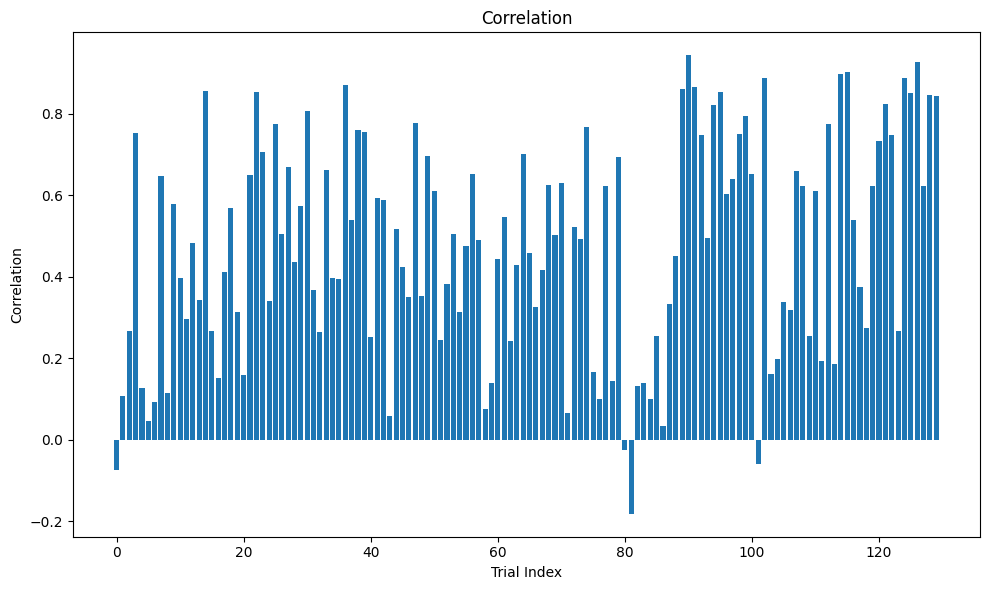

In [16]:
fsamp = 2048  

forces = []
min_len = float('inf')

for file_name in sorted_pkl_files:
    file_path = os.path.join(directory_path, file_name)
    
    with open(file_path, 'rb') as f:
        data = pickle.load(f)
    
    force_signal = np.array(data['Force'].tolist())[0]
    forces.append(force_signal)
    
    min_len = min(min_len, len(force_signal))

downsampled_forces = [resample(force, min_len) for force in forces]

last_five_forces = downsampled_forces[-5:]
average_last_five = np.mean(last_five_forces, axis=0)

correlations = []
for force in downsampled_forces:
    corr, _ = pearsonr(force, average_last_five)
    correlations.append(corr)

plt.figure(figsize=(10, 6))
plt.bar(range(len(correlations)), correlations)
plt.xlabel('Trial Index')
plt.ylabel('Correlation')
plt.title('Correlation')
plt.tight_layout()
# plt.savefig('/Users/nmt121/Desktop/figures/S1correlationpertrial.pdf', dpi=300, bbox_inches='tight')
plt.show()


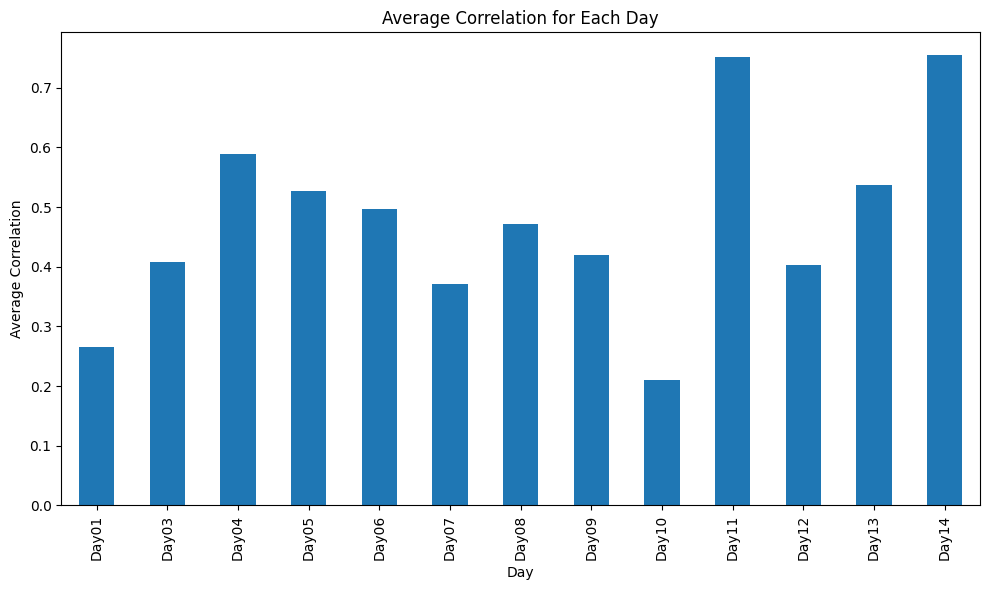

In [17]:
forces = []
min_len = float('inf')

for file_name in sorted_pkl_files:
    file_path = os.path.join(directory_path, file_name)
    
    with open(file_path, 'rb') as f:
        data = pickle.load(f)
    
    force_signal = np.array(data['Force'].tolist())[0]
    forces.append(force_signal)
    
    min_len = min(min_len, len(force_signal))

downsampled_forces = [resample(force, min_len) for force in forces]

last_five_forces = downsampled_forces[-5:]
average_last_five = np.mean(last_five_forces, axis=0)

correlations = []
for force in downsampled_forces:
    corr, _ = pearsonr(force, average_last_five)
    correlations.append(corr)

days = [re.search(r"(Day\d{2})", file).group(1) if re.search(r"(Day\d{2})", file) else None for file in sorted_pkl_files]

correlation_df = pd.DataFrame({'Trial': sorted_pkl_files,'Correlation': correlations,'Day': days})

average_correlation_per_day = correlation_df.groupby('Day')['Correlation'].mean()

average_correlation_per_day.plot(kind='bar', figsize=(10, 6))
plt.xlabel('Day')
plt.ylabel('Average Correlation')
plt.title('Average Correlation for Each Day')
plt.tight_layout()
# plt.savefig('/Users/nmt121/Desktop/figures/S1correlationaveragedperday.pdf', dpi=300, bbox_inches='tight')

plt.show()


/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_47021/1187996052.py:9: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = {day: plt.cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}


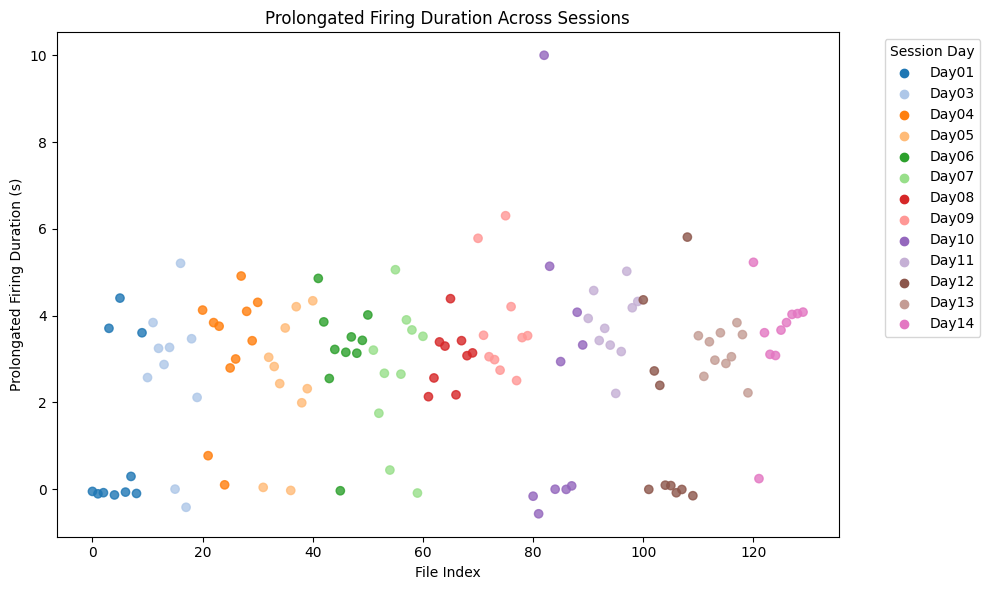

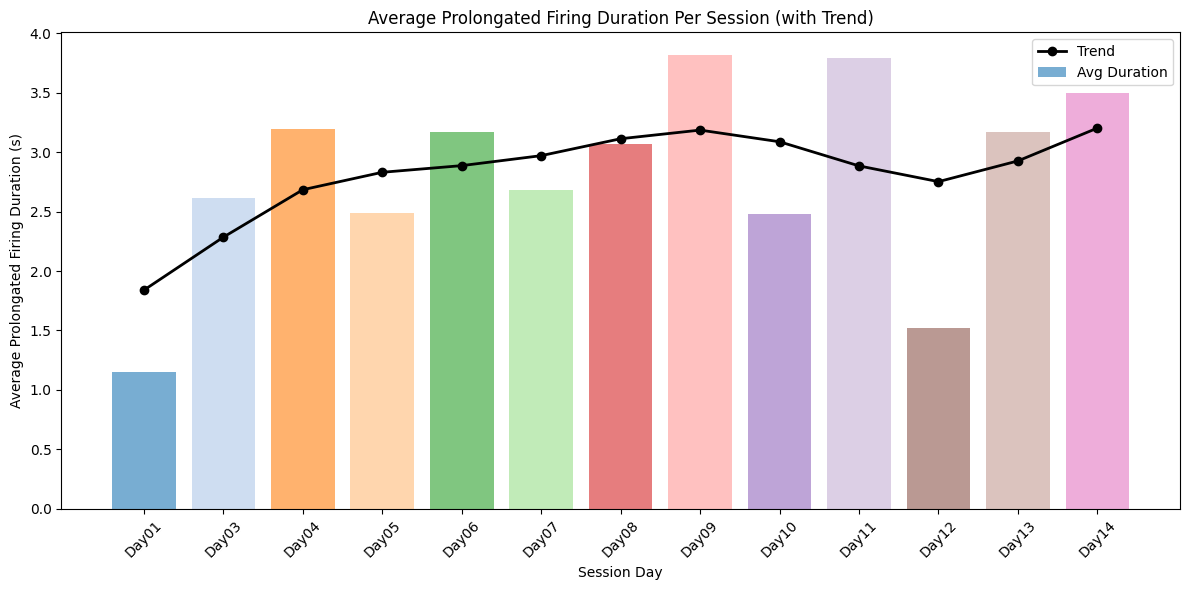

In [18]:
session_days = sorted(set([
    re.search(r"(Day\d{2})", file).group(1) if re.search(r"(Day\d{2})", file) else None 
    for file in sorted_pkl_files
]))  

num_days = len(session_days)  

if num_days <= 20:
    color_map = {day: plt.cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}
else:
    color_map = {day: plt.cm.viridis(i / num_days) for i, day in enumerate(session_days)}

num_files = len(sorted_pkl_files)  
total_dur = []  
colors = []  
day_durations = {day: [] for day in session_days}  

for i, file_name in enumerate(sorted_pkl_files):
    file_path = os.path.join(directory_path, file_name)  
    with open(file_path, 'rb') as f:
        data = pickle.load(f)  

    data_MU = np.array(data['MU'].tolist())  
    idx_pair = data['Idx_MU_Pair'].tolist()  

    spike_positions_small = np.where(data_MU[idx_pair[0]] == 1)[0]  
    spike_positions_large = np.where(data_MU[idx_pair[1]] == 1)[0]  

    if len(spike_positions_small) == 0 or len(spike_positions_large) == 0:
        continue  

    last_spike_position_small_mn = spike_positions_small[-1]  
    last_spike_position_large_mn = spike_positions_large[-1]  

    duration_prolongated_firing = (last_spike_position_large_mn - last_spike_position_small_mn) / fsamp  
    total_dur.append(duration_prolongated_firing)  

    session_day = re.search(r"(Day\d{2})", file_name).group(1) if re.search(r"(Day\d{2})", file_name) else None  
    colors.append(color_map[session_day])  
    day_durations[session_day].append(duration_prolongated_firing)  

day_avg_durations = {day: np.mean(durations) for day, durations in day_durations.items() if durations}  

time = np.arange(len(total_dur))  
plt.figure(figsize=(10, 6))  
plt.scatter(time, total_dur, color=colors, alpha=0.8)  

plt.xlabel("File Index")  
plt.ylabel("Prolongated Firing Duration (s)")  
plt.title("Prolongated Firing Duration Across Sessions")  

for day, color in color_map.items():
    plt.scatter([], [], color=color, label=day)  

plt.legend(title="Session Day", bbox_to_anchor=(1.05, 1), loc='upper left')  
plt.tight_layout()  
# plt.savefig('/Users/nmt121/Desktop/figures/S1.pdf', dpi=300, bbox_inches='tight')  

plt.show()  

sorted_days = sorted(day_avg_durations.keys(), key=lambda x: int(re.search(r'\d+', x).group()))  
sorted_avg_durations = [day_avg_durations[day] for day in sorted_days]  
smoothed_avg_durations = gaussian_filter1d(sorted_avg_durations, sigma=1.2)  

plt.figure(figsize=(12, 6))  
plt.bar(sorted_days, sorted_avg_durations, color=[color_map[day] for day in sorted_days], alpha=0.6, label="Avg Duration")  
plt.plot(sorted_days, smoothed_avg_durations, marker='o', linestyle='-', color='black', linewidth=2, label="Trend")  

plt.xlabel("Session Day")  
plt.ylabel("Average Prolongated Firing Duration (s)")  
plt.title("Average Prolongated Firing Duration Per Session (with Trend)")  

plt.xticks(rotation=45)  
plt.legend()  
plt.tight_layout()  
# plt.savefig('/Users/nmt121/Desktop/figures/S1trend.pdf', dpi=300, bbox_inches='tight')  

plt.show()  


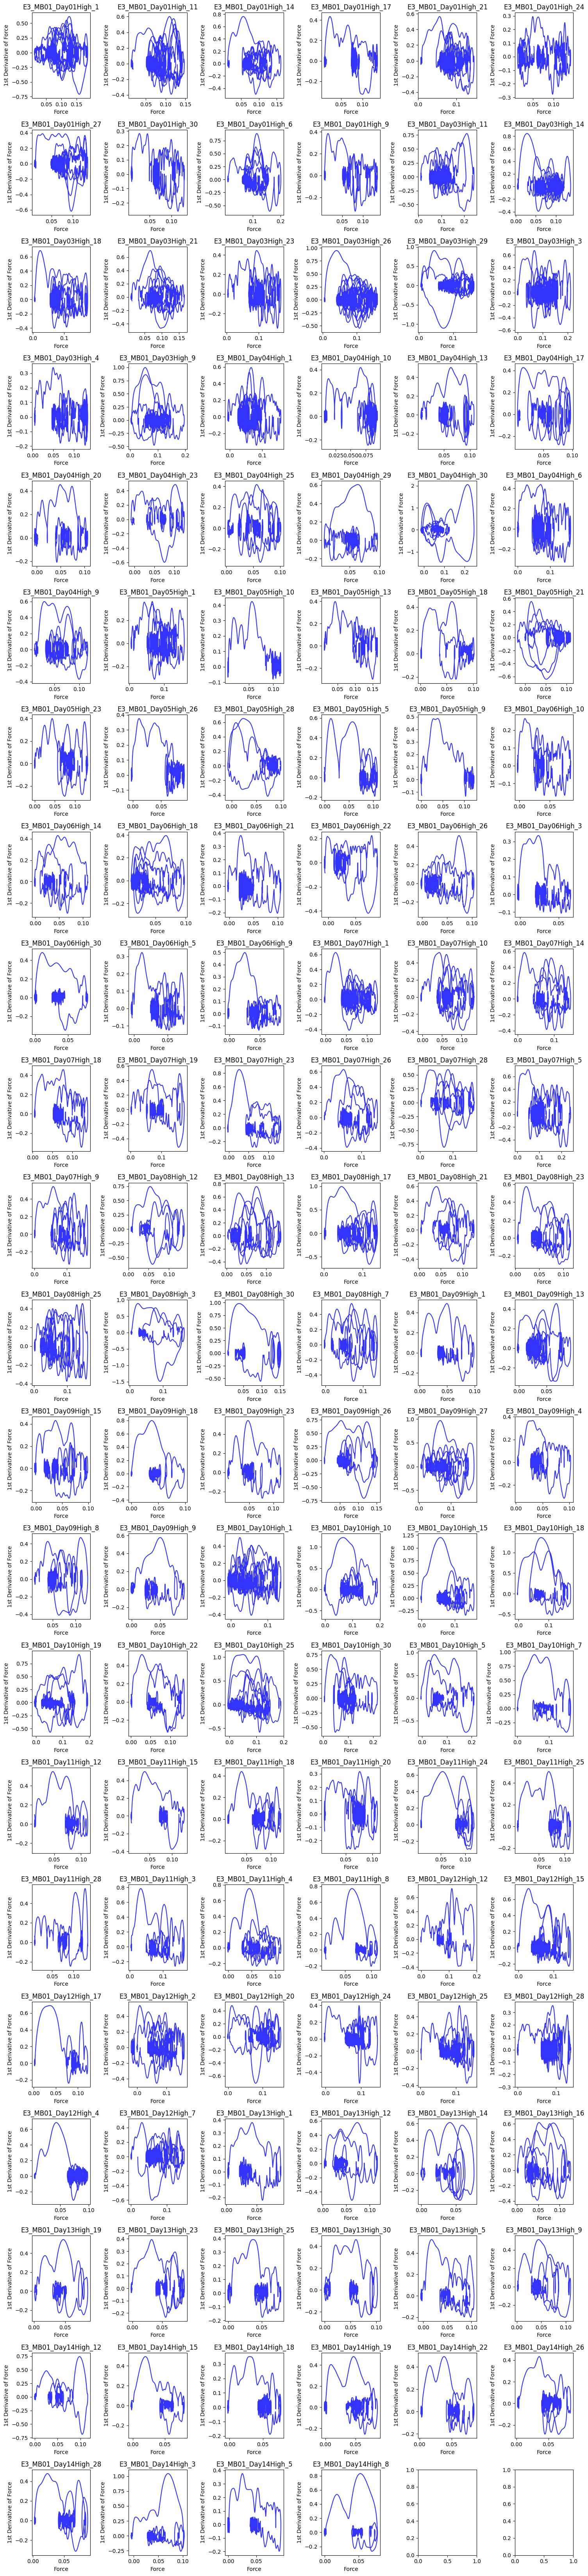

In [22]:
num_files = len(sorted_pkl_files)  
cols = 6  
rows = int(np.ceil(num_files / cols))  


fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 3))  
axes = axes.flatten()  

for i, file_name in enumerate(sorted_pkl_files):  
    file_path = os.path.join(directory_path, file_name)  
    with open(file_path, 'rb') as f:  
        data = pickle.load(f)  

    force_signal = np.array(data['Force']).flatten()  
    time_axis = np.arange(len(force_signal)) / fsamp  
    force_derivative = compute_derivative(force_signal, fsamp)  

    ax = axes[i]  
    ax.plot(force_signal, force_derivative, color="blue", alpha=0.8)  
    ax.set_title(file_name.split('.')[0])  
    ax.set_xlabel("Force")  
    ax.set_ylabel("1st Derivative of Force")  

plt.tight_layout()  
# plt.savefig('/Users/nmt121/Desktop/figures/S1forceandforcederivative.pdf', dpi=300, bbox_inches='tight')  

plt.show()  

/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_47021/3447522866.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = {day: plt.cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}


Skipping E3_MB01_Day05High_10.pkl: Trial is too short (0.00 sec)
Skipping E3_MB01_Day05High_9.pkl: Trial is too short (0.00 sec)


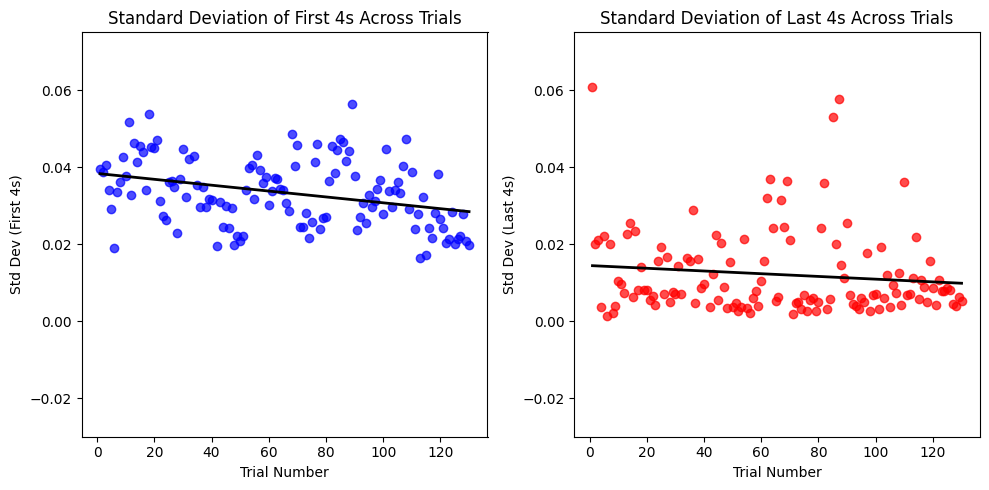

In [23]:
fsamp = 2048  
segment_duration = 4.5
highlight_samples = int(segment_duration * fsamp)  

session_days = sorted(set([re.search(r"(Day\d{2})", file).group(1) if re.search(r"(Day\d{2})", file) else None  for file in sorted_pkl_files]))  

num_days = len(session_days)  

if num_days <= 20:  
    color_map = {day: plt.cm.get_cmap("tab20")(i) for i, day in enumerate(session_days)}  
else:  
    color_map = {day: plt.cm.viridis(i / num_days) for i, day in enumerate(session_days)}  

num_files = len(sorted_pkl_files)  
std_first_segment = []  
std_last_segment = []  
trial_numbers = []  

for i, file_name in enumerate(sorted_pkl_files):  
    file_path = os.path.join(directory_path, file_name)  
    with open(file_path, 'rb') as f:  
        data = pickle.load(f)  

    data_FORCE = np.array(data['Force'])  

    if len(data_FORCE[0]) < highlight_samples:  
        print(f"Skipping {file_name}: Trial is too short ({len(data_FORCE)/fsamp:.2f} sec)")  
        continue  

    first_seg = data_FORCE[0][:highlight_samples]  
    last_seg = np.take(data_FORCE[0], range(len(data_FORCE) - highlight_samples, len(data_FORCE)))  

    std_first_segment.append(np.std(first_seg))  
    std_last_segment.append(np.std(last_seg))  
    trial_numbers.append(i + 1)  

std_first_segment = np.array(std_first_segment)  
std_last_segment = np.array(std_last_segment)  
trial_numbers = np.array(trial_numbers)  

if len(trial_numbers) > 1:  
    slope_first, intercept_first, _, _, _ = linregress(trial_numbers, std_first_segment)  
    trend_first = slope_first * trial_numbers + intercept_first  

    slope_last, intercept_last, _, _, _ = linregress(trial_numbers, std_last_segment)  
    trend_last = slope_last * trial_numbers + intercept_last  
else:  
    trend_first = std_first_segment  
    trend_last = std_last_segment  

plt.figure(figsize=(10, 5))  

plt.subplot(1, 2, 1)  
plt.scatter(trial_numbers, std_first_segment, color='blue', alpha=0.7, label="Raw Data")  
plt.plot(trial_numbers, trend_first, color='black', linewidth=2, label="Trend Line")  
plt.xlabel("Trial Number")  
plt.ylabel("Std Dev (First 4s)")  
plt.title("Standard Deviation of First 4s Across Trials")  
plt.grid(False)  
plt.ylim([-0.03, 0.075])  

plt.subplot(1, 2, 2)  
plt.scatter(trial_numbers, std_last_segment, color='red', alpha=0.7, label="Raw Data")  
plt.plot(trial_numbers, trend_last, color='black', linewidth=2, label="Trend Line")  
plt.xlabel("Trial Number")  
plt.ylabel("Std Dev (Last 4s)")  
plt.title("Standard Deviation of Last 4s Across Trials")  
plt.grid(False)  
plt.ylim([-0.03, 0.075])  
plt.tight_layout()  
# plt.savefig('/Users/nmt121/Desktop/figures/S1std.pdf', dpi=300, bbox_inches='tight')  

plt.show()  

